### 1. Load the dataset

In [1]:
from pathlib import Path
import cv2
import pandas as pd
import matplotlib.pyplot as plt

# Project directory
project_root = Path.cwd().parent

# Dataset directory
video_folder = (
    project_root
    / "data"
    / "datasets"
    / "GRID"
    / "speaker_01"
    / "raw_videos"
)

# Find all videos
video_files = sorted(video_folder.rglob("*.mpg"))
print("Dataset loaded successfully!")
print("Total videos:", len(video_files))

Dataset loaded successfully!
Total videos: 1000


### 2. Inspect the properties of all videos

In [2]:
video_information = []
for video_path in video_files:
    cap = cv2.VideoCapture(str(video_path))
    if cap.isOpened():
        width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
        height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
        fps = cap.get(cv2.CAP_PROP_FPS)
        frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
        duration = frame_count / fps if fps > 0 else 0
        video_information.append({
            "filename": video_path.name,
            "width": width,
            "height": height,
            "fps": fps,
            "frames": frame_count,
            "duration_seconds": duration
        })
    cap.release()

# Create a DataFrame
df_videos = pd.DataFrame(video_information)
print("Inspection completed!")
print("Number of readable videos:", len(df_videos))
df_videos.head(10)

Inspection completed!
Number of readable videos: 1000


,filename,width,height,fps,frames,duration_seconds
0,bbaf2n.mpg,360,288,25.0,75,3.0
1,bbaf3s.mpg,360,288,25.0,75,3.0
2,bbaf4p.mpg,360,288,25.0,75,3.0
3,bbaf5a.mpg,360,288,25.0,75,3.0
4,bbal6n.mpg,360,288,25.0,75,3.0
5,bbal7s.mpg,360,288,25.0,75,3.0
6,bbal8p.mpg,360,288,25.0,75,3.0
7,bbal9a.mpg,360,288,25.0,75,3.0
8,bbas1s.mpg,360,288,25.0,75,3.0
9,bbas2p.mpg,360,288,25.0,75,3.0


### 3. Calculate dataset statistics

In [3]:
print("DATASET STATISTICS")
print("------------------")
print("Number of videos:", len(df_videos))
print("\nResolution:")
print(df_videos["width"].value_counts())
print(df_videos["height"].value_counts())
print("\nFPS:")
print(df_videos["fps"].value_counts())
print("\nFrames:")
print(df_videos["frames"].describe())
print("\nDuration:")
print(df_videos["duration_seconds"].describe())

DATASET STATISTICS
------------------
Number of videos: 1000

Resolution:
width
360    1000
Name: count, dtype: int64
height
288    1000
Name: count, dtype: int64

FPS:
fps
25.0    1000
Name: count, dtype: int64

Frames:
count    1000.000000
mean       74.995000
std         0.070569
min        74.000000
25%        75.000000
50%        75.000000
75%        75.000000
max        75.000000
Name: frames, dtype: float64

Duration:
count    1000.000000
mean        2.999800
std         0.002823
min         2.960000
25%         3.000000
50%         3.000000
75%         3.000000
max         3.000000
Name: duration_seconds, dtype: float64


### 4. Visualize the distribution of video durations

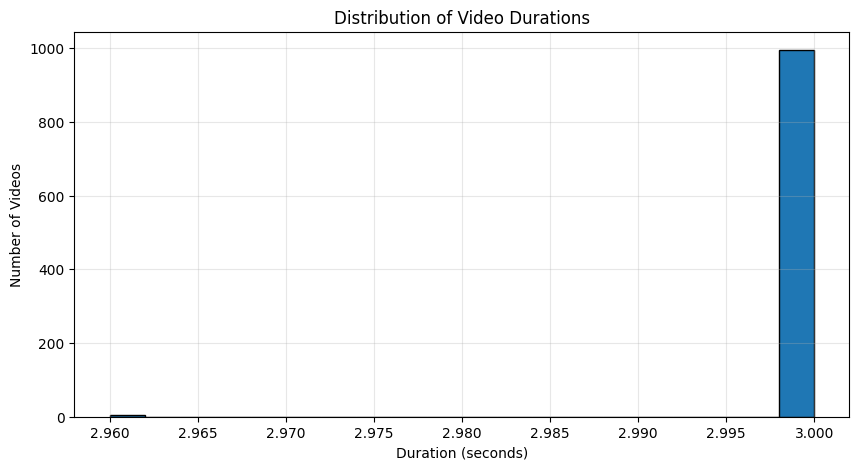

In [4]:
plt.figure(figsize=(10, 5))
plt.hist(df_videos["duration_seconds"], bins=20, edgecolor="black")
plt.title("Distribution of Video Durations")
plt.xlabel("Duration (seconds)")
plt.ylabel("Number of Videos")
plt.grid(alpha=0.3)
plt.show()

### 5. Save the inspection results

In [5]:
results_folder = (project_root / "results" / "dataset_inspection")
results_folder.mkdir(parents=True, exist_ok=True)
output_file = results_folder / "video_information.csv"
df_videos.to_csv(output_file, index=False)
print("Video information saved successfully!")
print(output_file)

Video information saved successfully!
c:\Users\linah\OneDrive\Documenti\GitHub\intelligent_lip_detection\results\dataset_inspection\video_information.csv
